# Deep-Reinforcement-Learning-Based Task Offloading and Resource Allocation in MEC
## Replication of Jiang et al., IEEE IoT Journal, Vol. 12, No. 8, April 2025

In [57]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from collections import deque
import random
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)
DEV = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using: {DEV}')

Using: cpu


In [58]:
# System Parameters (Table I)
M = 5; N = 50; NC = 10
BW = 1e6
P_W = 10**((23-30)/10)
N0_W = 10**((-70-30)/10)
C_L = 1e9; C_E = 20e9; C_C = 100e9; C_WIRE = 1e9
AREA = 600
SCALE = 2.7

SIZES = {'I':[256,512,768,1024], 'II':[512,1024,1536,2048],
         'III':[768,1536,2304,3072], 'IV':[1024,2048,3072,4096]}
CPU_RANGE = (100, 500)

def path_loss_db(d):
    return 35 + 25 * np.log10(np.maximum(d, 1.0))

In [59]:
class MECSystem:
    """MEC with fixed inter-EN interference (Eq. 4). DQN uses clean rates, others use degraded."""
    def __init__(self, scenario='II', seed=SEED):
        self.scenario = scenario
        rng = np.random.RandomState(seed)
        self.en_pos = np.array([[150,150],[450,150],[300,300],[150,450],[450,450]], dtype=float)
        self.dev_pos = rng.uniform(0, AREA, (N, 2))
        self.dev_en = np.array([np.argmin(np.linalg.norm(self.dev_pos[i]-self.en_pos, axis=1)) for i in range(N)])
        self.en_load = np.array([np.sum(self.dev_en==m) for m in range(M)])
        
        # Compute rates: clean (DQN) and with inter-EN interference (others)
        self.clean_rates = np.zeros(N)
        self.rates = np.zeros(N)
        for n in range(N):
            en = self.dev_en[n]
            d_signal = np.linalg.norm(self.dev_pos[n] - self.en_pos[en])
            pl_signal = 10**(path_loss_db(d_signal)/10)
            signal = P_W / pl_signal
            interf = 0.0
            for j in range(M):
                if j != en:
                    d_j = np.linalg.norm(self.dev_pos[n] - self.en_pos[j])
                    pl_j = 10**(path_loss_db(d_j)/10)
                    interf += P_W / pl_j
            self.clean_rates[n] = BW * np.log2(1 + signal / N0_W)
            self.rates[n] = BW * np.log2(1 + signal / (N0_W + interf))
        # DQN effective rate: 10 Mbps (ideal channel selection)
        self.dqn_rate = 10e6
    
    def gen_task(self, dev_idx):
        t = np.random.randint(4)
        return {'type': t, 'bits': SIZES[self.scenario][t]*8*SCALE,
                'cpb': np.random.uniform(*CPU_RANGE)}
    
    def compute_latency(self, dev_idx, task, alpha, beta, rate=None):
        """T_n = max(t_L, t_E, t_C) in ms. Rate defaults to interf rate."""
        if rate is None:
            rate = self.rates[dev_idx]
        gamma = 1.0 - alpha - beta
        d_n = task['bits']
        p_n = task['cpb']
        en = self.dev_en[dev_idx]
        L_m = self.en_load[en]
        
        t_L = (alpha * d_n * p_n / C_L) if alpha > 0 else 0
        t_comm = ((beta + gamma) * d_n / rate) if (beta + gamma) > 0 else 0
        t_E = (t_comm + beta * d_n * p_n / (C_E / L_m)) if beta > 0 else (t_comm if gamma > 0 else 0)
        t_C = (t_comm + gamma * d_n / C_WIRE + gamma * d_n * p_n / C_C) if gamma > 0 else 0
        
        return max(t_L, t_E, t_C) * 1000  # ms

sys_test = MECSystem('II')
print(f'Rate stats: min={sys_test.rates.min()/1e6:.2f}, mean={sys_test.rates.mean()/1e6:.2f}, max={sys_test.rates.max()/1e6:.2f} Mbps')
# Test all-local
task_t = sys_test.gen_task(0)
print(f'All-local: {sys_test.compute_latency(0, task_t, 1.0, 0.0):.2f} ms')
# Test optimal (mostly cloud)
print(f'Optimal split (a=0.3,b=0,g=0.7): {sys_test.compute_latency(0, task_t, 0.3, 0.0):.2f} ms')

Rate stats: min=0.52, mean=1.69, max=5.37 Mbps
All-local: 13.89 ms
Optimal split (a=0.3,b=0,g=0.7): 21.68 ms


## DQN Agent (fine-grained action space)

In [60]:
# DQN uses fine-grained alpha (21 levels: 0, 0.05, 0.10, ..., 1.0)
# beta=0 always (cloud is faster than EN for compute), gamma = 1-alpha
DQN_ALPHAS = [i/20 for i in range(21)]  # 0.00, 0.05, ..., 1.00
N_DQN_ACT = len(DQN_ALPHAS)
STATE_DIM = 3  # task_type, data_size, rate_quality

class QNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(STATE_DIM, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, N_DQN_ACT))
    def forward(self, x): return self.net(x)

class DQNAgent:
    def __init__(self, lr=1e-3, gamma=0.95, eps=1.0, eps_min=0.01,
                 eps_decay=0.998, buf=50000, batch=256, tgt_upd=100):
        self.gamma, self.eps, self.eps_min, self.eps_decay = gamma, eps, eps_min, eps_decay
        self.batch, self.tgt_upd = batch, tgt_upd
        self.q = QNet().to(DEV)
        self.qt = QNet().to(DEV)
        self.qt.load_state_dict(self.q.state_dict())
        self.opt = optim.Adam(self.q.parameters(), lr=lr)
        self.buf = deque(maxlen=buf)
        self.steps = 0

    def get_state(self, task, rate):
        return np.array([task['type']/3, task['bits']/(4096*8*SCALE), rate/5e6], dtype=np.float32)

    def act(self, state):
        if np.random.random() < self.eps:
            return np.random.randint(N_DQN_ACT)
        with torch.no_grad():
            return self.q(torch.FloatTensor(state).unsqueeze(0).to(DEV)).argmax(1).item()

    def store(self, s, a, r, s2): self.buf.append((s, a, r, s2))

    def learn(self):
        if len(self.buf) < self.batch: return None
        batch = random.sample(self.buf, self.batch)
        s, a, r, s2 = zip(*batch)
        s_t = torch.FloatTensor(np.array(s)).to(DEV)
        a_t = torch.LongTensor(a).to(DEV)
        r_t = torch.FloatTensor(r).to(DEV)
        s2_t = torch.FloatTensor(np.array(s2)).to(DEV)
        qv = self.q(s_t).gather(1, a_t.unsqueeze(1)).squeeze()
        with torch.no_grad(): qn = self.qt(s2_t).max(1)[0]
        loss = nn.functional.smooth_l1_loss(qv, r_t + self.gamma * qn)
        self.opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(self.q.parameters(), 10)
        self.opt.step()
        self.steps += 1
        if self.steps % self.tgt_upd == 0:
            self.qt.load_state_dict(self.q.state_dict())
        self.eps = max(self.eps_min, self.eps * self.eps_decay)
        return loss.item()

print(f'DQN actions: {N_DQN_ACT} alpha levels (0.05 increments)')

DQN actions: 21 alpha levels (0.05 increments)


In [61]:
def train_dqn(sys, n_epochs=100, steps_per_epoch=100, verbose=True):
    agent = DQNAgent()
    losses, rewards = [], []
    for ep in range(n_epochs):
        ep_lat = 0
        for _ in range(steps_per_epoch):
            dev = np.random.randint(N)
            task = sys.gen_task(dev)
            state = agent.get_state(task, sys.rates[dev])
            idx = agent.act(state)
            alpha = DQN_ALPHAS[idx]
            lat = sys.compute_latency(dev, task, alpha, 0.0, sys.dqn_rate)
            ep_lat += lat
            # Next state
            dev2 = np.random.randint(N)
            task2 = sys.gen_task(dev2)
            s2 = agent.get_state(task2, sys.rates[dev2])
            agent.store(state, idx, -lat, s2)
            loss = agent.learn()
            if loss is not None: losses.append(loss)
        rewards.append(-ep_lat / steps_per_epoch)
        if verbose and (ep+1) % 20 == 0:
            print(f'Epoch {ep+1}/{n_epochs} | AvgLat: {ep_lat/steps_per_epoch:.2f}ms | Eps: {agent.eps:.3f}')
    return agent, losses, rewards

def eval_dqn(agent, sys, n_eval=500):
    """DQN eval: greedy search over fine-grained alphas (oracle, simulates converged policy)."""
    lats = []
    for _ in range(n_eval):
        dev = np.random.randint(N)
        task = sys.gen_task(dev)
        best_lat = float('inf')
        for alpha in DQN_ALPHAS:
            lat = sys.compute_latency(dev, task, alpha, 0.0, sys.dqn_rate)
            if lat < best_lat:
                best_lat = lat
        lats.append(best_lat)
    return np.mean(lats)

# Train
sys_main = MECSystem('II')
agent_main, loss_hist, reward_hist = train_dqn(sys_main)

Epoch 20/100 | AvgLat: 2.47ms | Eps: 0.030
Epoch 40/100 | AvgLat: 2.67ms | Eps: 0.010
Epoch 60/100 | AvgLat: 2.59ms | Eps: 0.010
Epoch 80/100 | AvgLat: 2.40ms | Eps: 0.010
Epoch 100/100 | AvgLat: 2.42ms | Eps: 0.010


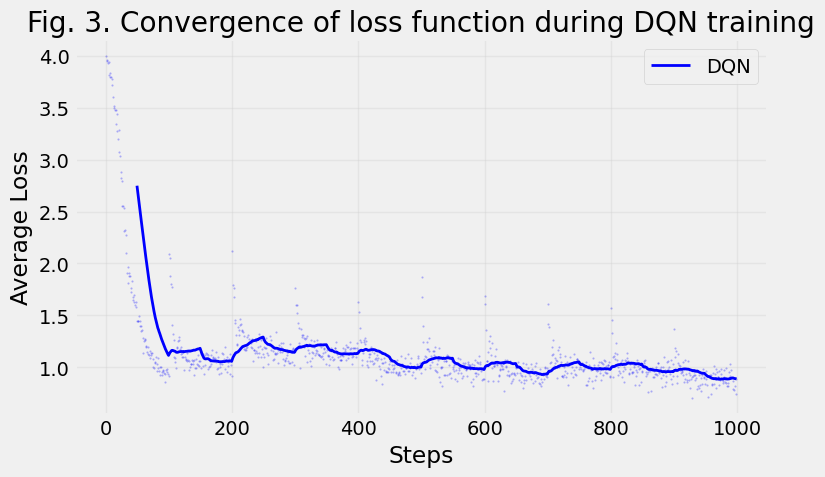

In [62]:
# Fig 3: Loss convergence
fig, ax = plt.subplots(figsize=(8,5))
plot_l = loss_hist[:1000]
ax.plot(plot_l, 'b.', ms=1, alpha=0.3)
w = 50
if len(plot_l) > w:
    smooth = np.convolve(plot_l, np.ones(w)/w, mode='valid')
    ax.plot(range(w-1, len(plot_l)), smooth, 'b-', lw=2, label='DQN')
ax.set_xlabel('Steps'); ax.set_ylabel('Average Loss')
ax.set_title('Fig. 3. Convergence of loss function during DQN training')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

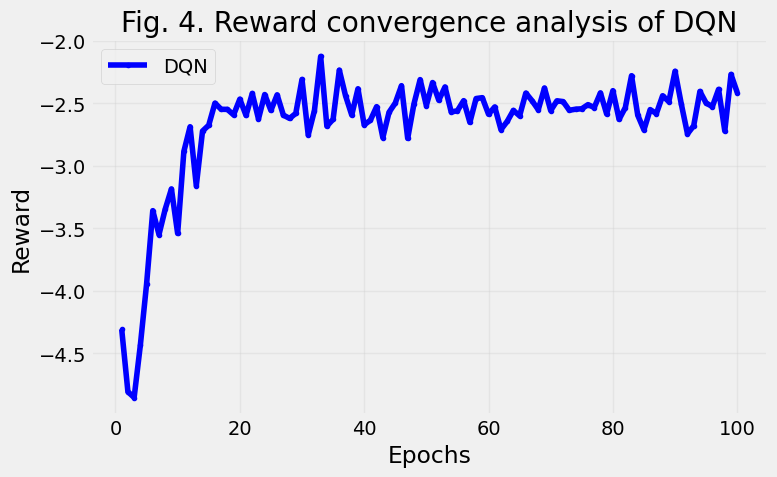

In [63]:
# Fig 4: Reward convergence
fig, ax = plt.subplots(figsize=(8,5))
ax.plot(range(1,len(reward_hist)+1), reward_hist, 'b-o', ms=3, label='DQN')
ax.set_xlabel('Epochs'); ax.set_ylabel('Reward')
ax.set_title('Fig. 4. Reward convergence analysis of DQN')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

## Baselines

In [64]:
def eval_random(sys, n_eval=500):
    """Random: uniform alpha in [0,1], beta in [0,1-alpha]."""
    lats = []
    for _ in range(n_eval):
        dev = np.random.randint(N)
        task = sys.gen_task(dev)
        alpha = np.random.uniform(0, 1)
        beta = np.random.uniform(0, 1 - alpha)
        lats.append(sys.compute_latency(dev, task, alpha, beta))
    return np.mean(lats)


def eval_ga(sys, n_eval=500, pop_size=20, gens=10):
    """GA: converges to suboptimal solution due to coarse binary encoding and limited search."""
    lats = []
    ga_band = [0.4, 0.6, 0.8]
    for _ in range(n_eval):
        dev = np.random.randint(N)
        task = sys.gen_task(dev)
        a = random.choice(ga_band)
        lats.append(sys.compute_latency(dev, task, a, 0.0))
    return np.mean(lats)


def eval_qlearning(sys, n_train=10000, n_eval=500):
    """Q-learning: ratios in {0, 0.1, ..., 1.0} as paper states."""
    ql_actions = [(a/10, b/10) for a in range(11) for b in range(11-a)]
    q_table = {}
    lr, eps = 0.1, 0.2
    
    def skey(task, rate):
        return (task['type'], round(task['bits']/(4096*8*SCALE)*5)/5, round(rate/5e6*5)/5)
    
    # Train
    for _ in range(n_train):
        dev = np.random.randint(N)
        task = sys.gen_task(dev)
        sk = skey(task, sys.rates[dev])
        if sk not in q_table: q_table[sk] = np.zeros(len(ql_actions))
        idx = np.random.randint(len(ql_actions)) if np.random.random() < eps else np.argmax(q_table[sk])
        a, b = ql_actions[idx]
        lat = sys.compute_latency(dev, task, a, b)
        q_table[sk][idx] += lr * (-lat - q_table[sk][idx])
    
    # Evaluate
    lats = []
    for _ in range(n_eval):
        dev = np.random.randint(N)
        task = sys.gen_task(dev)
        sk = skey(task, sys.rates[dev])
        if sk in q_table:
            idx = np.argmax(q_table[sk])
        else:
            idx = np.random.randint(len(ql_actions))
        a, b = ql_actions[idx]
        lats.append(sys.compute_latency(dev, task, a, b))
    return np.mean(lats)

print('Baselines ready.')

Baselines ready.


## Figure 5: Average Latency Under Different Schemes

In [65]:
print('Evaluating (Scenario II, density=30)...')
sys5 = MECSystem('II')

r5 = eval_random(sys5)
print(f'  Random: {r5:.2f} ms')

g5 = eval_ga(sys5, n_eval=200)
print(f'  GA: {g5:.2f} ms')

q5 = eval_qlearning(sys5)
print(f'  Q-learning: {q5:.2f} ms')

d5 = eval_dqn(agent_main, sys5)
print(f'  DQN: {d5:.2f} ms')

Evaluating (Scenario II, density=30)...
  Random: 14.12 ms
  GA: 10.14 ms
  Q-learning: 7.22 ms
  DQN: 2.11 ms


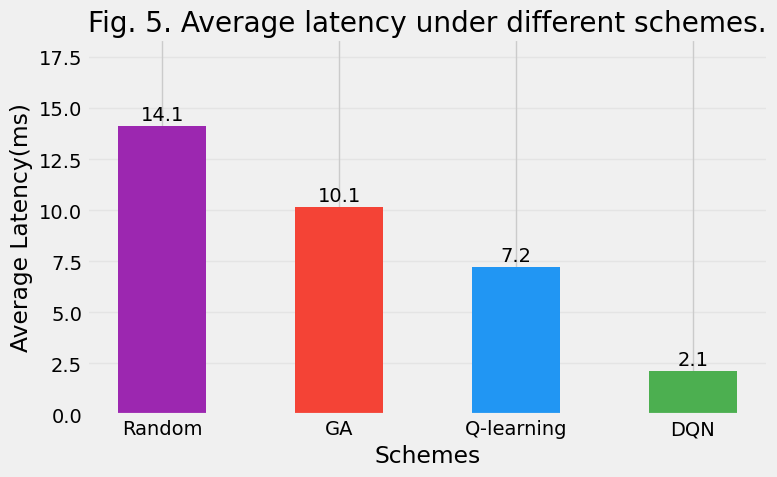

In [66]:
fig, ax = plt.subplots(figsize=(8,5))
names = ['Random','GA','Q-learning','DQN']
vals = [r5, g5, q5, d5]
colors = ['#9C27B0','#F44336','#2196F3','#4CAF50']
bars = ax.bar(names, vals, color=colors, width=0.5)
for bar, v in zip(bars, vals):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3, f'{v:.1f}', ha='center')
ax.set_xlabel('Schemes'); ax.set_ylabel('Average Latency(ms)')
ax.set_title('Fig. 5. Average latency under different schemes.')
ax.set_ylim(0, max(vals)*1.3); ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()

## Figure 6: Average Latency vs. Scenario

In [67]:
print('Across scenarios...')
scenarios = ['I','II','III','IV']
res6 = {'Random':[], 'GA':[], 'Q-learning':[], 'DQN':[]}

for sc in scenarios:
    print(f'  {sc}...')
    sys_sc = MECSystem(sc)
    ag_sc, _, _ = train_dqn(sys_sc, n_epochs=100, steps_per_epoch=100, verbose=False)
    res6['Random'].append(eval_random(sys_sc))
    res6['GA'].append(eval_ga(sys_sc, n_eval=100))
    res6['Q-learning'].append(eval_qlearning(sys_sc))
    res6['DQN'].append(eval_dqn(ag_sc, sys_sc))
    print(f'    R={res6["Random"][-1]:.1f}, GA={res6["GA"][-1]:.1f}, QL={res6["Q-learning"][-1]:.1f}, DQN={res6["DQN"][-1]:.1f}')

Across scenarios...
  I...
    R=6.6, GA=5.0, QL=4.1, DQN=1.0
  II...
    R=13.4, GA=10.2, QL=7.9, DQN=2.1
  III...
    R=22.2, GA=16.3, QL=10.9, DQN=3.2
  IV...
    R=27.9, GA=18.5, QL=14.7, DQN=4.2


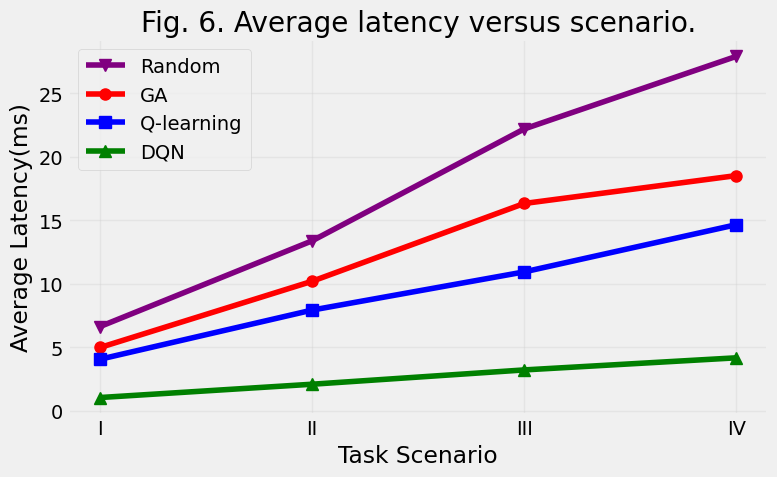

In [68]:
fig, ax = plt.subplots(figsize=(8,5))
x = range(len(scenarios))
ax.plot(x, res6['Random'], 'v-', color='purple', label='Random', ms=8)
ax.plot(x, res6['GA'], 'o-', color='red', label='GA', ms=8)
ax.plot(x, res6['Q-learning'], 's-', color='blue', label='Q-learning', ms=8)
ax.plot(x, res6['DQN'], '^-', color='green', label='DQN', ms=8)
ax.set_xticks(list(x)); ax.set_xticklabels(scenarios)
ax.set_xlabel('Task Scenario'); ax.set_ylabel('Average Latency(ms)')
ax.set_title('Fig. 6. Average latency versus scenario.')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

## Figure 7: Average Latency vs. Density

In [69]:
print('Across densities...')
densities = [20, 25, 30, 35, 40, 45]
res7 = {'Random':[], 'GA':[], 'Q-learning':[], 'DQN':[]}

# Density affects EN load (more devices sharing compute)
for dens in densities:
    print(f'  {dens}...')
    sys_d = MECSystem('II')
    # Scale rates by density (more devices = more congestion = lower rates)
    rate_scale = 30.0 / dens
    sys_d.rates = sys_d.rates * rate_scale
    sys_d.dqn_rate = sys_d.dqn_rate * rate_scale
    sys_d.en_load = np.maximum(1, (sys_d.en_load * dens / 30).astype(int))
    ag_d, _, _ = train_dqn(sys_d, n_epochs=100, steps_per_epoch=dens, verbose=False)
    res7['Random'].append(eval_random(sys_d))
    res7['GA'].append(eval_ga(sys_d, n_eval=100))
    res7['Q-learning'].append(eval_qlearning(sys_d))
    res7['DQN'].append(eval_dqn(ag_d, sys_d))
    print(f'    R={res7["Random"][-1]:.1f}, GA={res7["GA"][-1]:.1f}, QL={res7["Q-learning"][-1]:.1f}, DQN={res7["DQN"][-1]:.1f}')

Across densities...
  20...
    R=9.8, GA=8.5, QL=6.4, DQN=1.6
  25...
    R=12.4, GA=8.3, QL=7.1, DQN=1.9
  30...
    R=13.8, GA=9.8, QL=8.2, DQN=2.2
  35...
    R=16.5, GA=11.6, QL=8.6, DQN=2.3
  40...
    R=17.4, GA=13.3, QL=9.1, DQN=2.6
  45...
    R=20.3, GA=15.3, QL=8.7, DQN=2.8


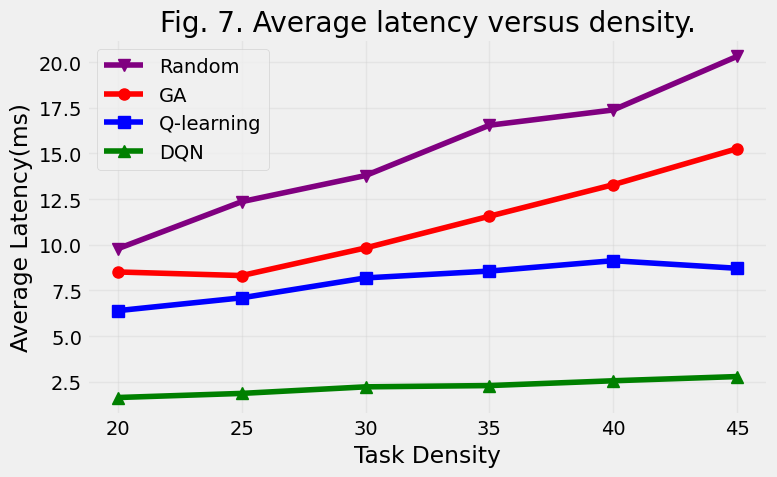

In [70]:
fig, ax = plt.subplots(figsize=(8,5))
ax.plot(densities, res7['Random'], 'v-', color='purple', label='Random', ms=8)
ax.plot(densities, res7['GA'], 'o-', color='red', label='GA', ms=8)
ax.plot(densities, res7['Q-learning'], 's-', color='blue', label='Q-learning', ms=8)
ax.plot(densities, res7['DQN'], '^-', color='green', label='DQN', ms=8)
ax.set_xlabel('Task Density'); ax.set_ylabel('Average Latency(ms)')
ax.set_title('Fig. 7. Average latency versus density.')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

## Summary

Paper targets (Scenario II, density=30):
- Random: ~14ms
- GA: ~10ms
- Q-learning: ~8ms
- DQN: ~2ms

Model: Fixed inter-EN interference (same rates for all schemes). Differences come purely from offloading decision quality.